# Снижение активности по картам: кто, насколько и за счёт чего

**Автор: Бондарев Виктор Александрович**
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, HTML, display

clean = pd.read_parquet("clean_data.parquet")
txn = pd.read_parquet("clean_transactions.parquet")
ops_long = pd.read_parquet("monthly_ops.parquet")
camp = pd.read_csv("campaign_list.csv")
log = pd.read_csv("cleaning_log.csv")
hyp = pd.read_csv("hypotheses.csv")

In [20]:
S6 = clean.season_S6.iloc[0]
BASE = pd.period_range("2024-01", "2024-12", freq="M"); EVAL = pd.period_range("2025-01", "2025-06", freq="M")
ALL = BASE.append(EVAL)
el = clean[clean.eligible_base].copy()
el["mass"] = np.where(el.segment == "Массовый", "Массовый", "Прочие сегменты")
purch = txn[txn.is_purchase & txn.client_status.eq("in_reference")].copy()
purch["per"] = np.where(purch.month < "2025-01", "base", "eval")
purch_el = purch[purch.client_id.isin(el.client_id)]

def ratio(d):
    """Индекс активности группы: (покупок в мес. 2025) / (ожидаемо по 2024 с сезонной поправкой). 1 = без изменений."""
    return d.eval_pm.sum() / (d.base_pm.sum() * S6)

def pc(x, plus=True):
    """Процентное изменение как строка"""
    s = f"{x:+.0%}" if plus else f"{x:.0%}"
    return s.replace("-", "−")

def num(x):
    return f"{x:,.0f}".replace(",", " ")

n_clients_raw = 5728
n_ref = len(clean); n_el = len(el)
r_port = ratio(el); r_port_raw = el.eval_pm.sum() / el.base_pm.sum()
r_mass = ratio(el[el.segment == "Массовый"]); r_rest = ratio(el[el.segment != "Массовый"])
lost = (el.base_pm * S6 - el.eval_pm)
share_mass_loss = lost[el.segment == "Массовый"].sum() / lost.sum()
r_noapp = ratio(el[(el.segment == "Массовый") & ~el.has_mobile_app])
r_app   = ratio(el[(el.segment == "Массовый") &  el.has_mobile_app])

groups = [
    "Г1 Массовый без приложения: затухание",
    "Г2 Массовый с приложением: общее снижение",
    "Г3 Ценные без приложения: общее снижение",
    "Г4 Отказ от пластика без перехода на Токен",
]
gsize = camp.group.value_counts().reindex(groups)

tk = purch_el.groupby("per").amount_rub.median(); tk_ratio = tk["eval"] / tk["base"]
cb = purch_el.groupby(["channel", "per"]).size().unstack()
ch_change = (cb["eval"] / 6) / (cb["base"] / 12) / S6 - 1
cat_b = purch_el.groupby(["category", "per"]).size().unstack()
cat_ratio_all = (cat_b["eval"] / 6) / (cat_b["base"] / 12) / S6

elo = clean[clean.eligible_base & clean.opt_in]
bg = elo.groupby(elo.segment == "Массовый").broad_fall.mean()
bg_ratio_rest = ratio(elo[elo.segment != "Массовый"])
rho_max = (el[["age", "tenure_years", "monthly_income", "base_pm", "ratio6"]]
             .corr(method="spearman")["ratio6"].drop("ratio6").abs().max())
fx = (txn[txn.currency != "RUB"]
        .assign(r=lambda d: d.amount_rub / d.amount)
        .groupby("currency").r.median())

def mass_broad(r6, r3, app, a, b):
    return (clean.eligible_base & clean.opt_in &
            (clean.segment == "Массовый") &
            (clean.has_mobile_app == app) &
            (clean[r6] <= a) & (clean[r3] <= b))

def keep(app, a, b, r6="ratio6", r3="ratio3"):
    main = clean.group == groups[0 if not app else 1]
    return (mass_broad(r6, r3, app, a, b) & main).sum() / main.sum()

## 1. Главное

<!-- 3–5 выводов с числами. Пишется последним, читается первым.
     Каждый вывод — утверждение, а не тема. Не «анализ активности»,
     а «активность упала на X% у группы Y за счёт Z». -->


In [37]:
display(Markdown(f"""
1. **Активность по картам упала на {abs(r_port - 1):.0%}** (успешные покупки в месяц, янв–июнь 2025 к 2024 с сезонной поправкой; {num(n_el)} клиентов). Без поправки было бы {abs(r_port_raw - 1):.0%}.
2. **Падает в основном Массовый сегмент: {pc(r_mass - 1)}**, на него приходится {share_mass_loss:.0%} недобора. Остальные сегменты держатся ({pc(r_rest - 1)}). Внутри Массового без приложения {pc(r_noapp - 1)}, с приложением {pc(r_app - 1)}.
3. **Реже, а не меньше:** медианный чек {tk_ratio:.2f} к 2024, падение идёт по всем каналам и категориям — это потеря привычки платить, а не одной категории. «Карта» {pc(ch_change['Карта'])}, «Токен» {pc(ch_change['Токен'])}: часть ушла в смартфон, их в кампанию не берём.
4. **В кампанию — {num(len(camp))} клиентов из бюджета 2 000 в четырёх группах:** {num(gsize.iloc[0])} (Массовый без приложения — затухание), {num(gsize.iloc[1])} (Массовый с приложением — общее снижение), {num(gsize.iloc[2])} (Ценные без приложения — общее снижение), {num(gsize.iloc[3])} (отказ от пластика без перехода на «Токен»). Каждый клиент в одной группе (правило разрешения конфликтов Г1 → Г2 → Г3 → Г4), у всех — согласие на коммуникацию.
"""))


1. **Активность по картам упала на 15%** (успешные покупки в месяц, янв–июнь 2025 к 2024 с сезонной поправкой; 4 756 клиентов). Без поправки было бы 21%.
2. **Падает в основном Массовый сегмент: −27%**, на него приходится 84% недобора. Остальные сегменты держатся (−4%). Внутри Массового без приложения −38%, с приложением −21%.
3. **Реже, а не меньше:** медианный чек 0.89 к 2024, падение идёт по всем каналам и категориям — это потеря привычки платить, а не одной категории. «Карта» −26%, «Токен» +37%: часть ушла в смартфон, их в кампанию не берём.
4. **В кампанию — 1 200 клиентов из бюджета 2 000 в четырёх группах:** 435 (Массовый без приложения — затухание), 391 (Массовый с приложением — общее снижение), 211 (Ценные без приложения — общее снижение), 163 (отказ от пластика без перехода на «Токен»). Каждый клиент в одной группе (правило разрешения конфликтов Г1 → Г2 → Г3 → Г4), у всех — согласие на коммуникацию.


## 2. Контекст

<!-- Какое решение поддерживает этот отчёт, 3–5 предложений. -->

In [22]:
display(Markdown(f"""
Департамент розничных продуктов планирует кампанию по возврату активности по картам. Бюджет — не более 2 000 клиентов, групп от 3 до 5 (каждая не меньше 150 человек), у каждой должно быть правило отбора и понятная причина падения; связываться можно только с давшими согласие.
Отчёт отвечает на вопросы: *кто снизил активность, насколько и за счёт чего*, и даёт список для кампании. Банк «Меридиан» и данные синтетические.
"""))


Департамент розничных продуктов планирует кампанию по возврату активности по картам. Бюджет — не более 2 000 клиентов, групп от 3 до 5 (каждая не меньше 150 человек), у каждой должно быть правило отбора и понятная причина падения; связываться можно только с давшими согласие.
Отчёт отвечает на вопросы: *кто снизил активность, насколько и за счёт чего*, и даёт список для кампании. Банк «Меридиан» и данные синтетические.


## 3. Данные и ограничения

<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->

In [23]:
n_txn =  len(txn)
n_txn_raw = n_txn + 1256 + 244 + 81
orph = txn[txn.client_status == "not_in_reference"].client_id.nunique()
excl = clean.exclusion_reason.value_counts()
display(Markdown(f"""
**Источники и период.** `clients.csv` — {num(n_clients_raw)} строк → {num(n_ref)} уникальных клиентов, пригодных к анализу; `transactions.csv` — {num(n_txn_raw)} операций → {num(n_txn)} после очистки (дубли, операции вне периода 2024-01-01…2025-06-30). База — 2024 год (12 мес.), оцениваемый период — январь–июнь 2025 (6 мес.), поэтому везде **средние в месяц**.

**Метрика активности.** Активность клиента — число *успешных покупок* по картам в месяц во всех каналах (Карта, Токен, СБП, Онлайн-банк); отклонённые операции и возвраты не считаются. Индекс активности = (покупок в месяц в 2025) / (покупок в месяц в 2024 × сезонный коэффициент {S6:.2f}); 1 — без изменений, 0,5 — упала вдвое. Коэффициент убирает влияние декабрьского пика и январского минимума, оценён только по 2024 году. **Метрика не видит:** снижение суммы чека при том же числе покупок; клиентов с малой или нулевой базой; уход в наличные или в другой банк (виден лишь «ноль» без причины); падение внутри последнего месяца; изменение состава трат при том же числе операций.

**Что исключено из расчёта и почему.** Клиенты с картой, открытой в 2024–2025 (нет полного базового года): {excl.get('Нет полного базового года: карта открыта в 2024–2025', 0)}; клиенты с менее чем 2 покупками в месяц в 2024 (индекс шумит): {excl.get('Мало операций в базе (<2 в месяц): падение не измерить', 0)}; {orph} клиентов в операциях, которых нет в справочнике действующих (ушли из банка — их операции исчезают к марту 2025).
Итого в сравнении участвуют **{num(n_el)}** клиентов.

**Чего в данных нет:** причин падения (опрос по удовлетворённости заполнен лишь у {clean.satisfaction_answered.mean():.0%} клиентов), данных о наличных и других банках, остатков и зарплатных поступлений. Данные охватывают один сезонный цикл, поэтому выводы о тренде осторожны.
"""))


**Источники и период.** `clients.csv` — 5 728 строк → 5 673 уникальных клиентов, пригодных к анализу; `transactions.csv` — 627 703 операций → 626 122 после очистки (дубли, операции вне периода 2024-01-01…2025-06-30). База — 2024 год (12 мес.), оцениваемый период — январь–июнь 2025 (6 мес.), поэтому везде **средние в месяц**.

**Метрика активности.** Активность клиента — число *успешных покупок* по картам в месяц во всех каналах (Карта, Токен, СБП, Онлайн-банк); отклонённые операции и возвраты не считаются. Индекс активности = (покупок в месяц в 2025) / (покупок в месяц в 2024 × сезонный коэффициент 0.93); 1 — без изменений, 0,5 — упала вдвое. Коэффициент убирает влияние декабрьского пика и январского минимума, оценён только по 2024 году. **Метрика не видит:** снижение суммы чека при том же числе покупок; клиентов с малой или нулевой базой; уход в наличные или в другой банк (виден лишь «ноль» без причины); падение внутри последнего месяца; изменение состава трат при том же числе операций.

**Что исключено из расчёта и почему.** Клиенты с картой, открытой в 2024–2025 (нет полного базового года): 772; клиенты с менее чем 2 покупками в месяц в 2024 (индекс шумит): 133; 327 клиентов в операциях, которых нет в справочнике действующих (ушли из банка — их операции исчезают к марту 2025).
Итого в сравнении участвуют **4 756** клиентов.

**Чего в данных нет:** причин падения (опрос по удовлетворённости заполнен лишь у 40% клиентов), данных о наличных и других банках, остатков и зарплатных поступлений. Данные охватывают один сезонный цикл, поэтому выводы о тренде осторожны.


## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. Падает Массовый сегмент: остальные сегменты держатся на уровне прошлого года

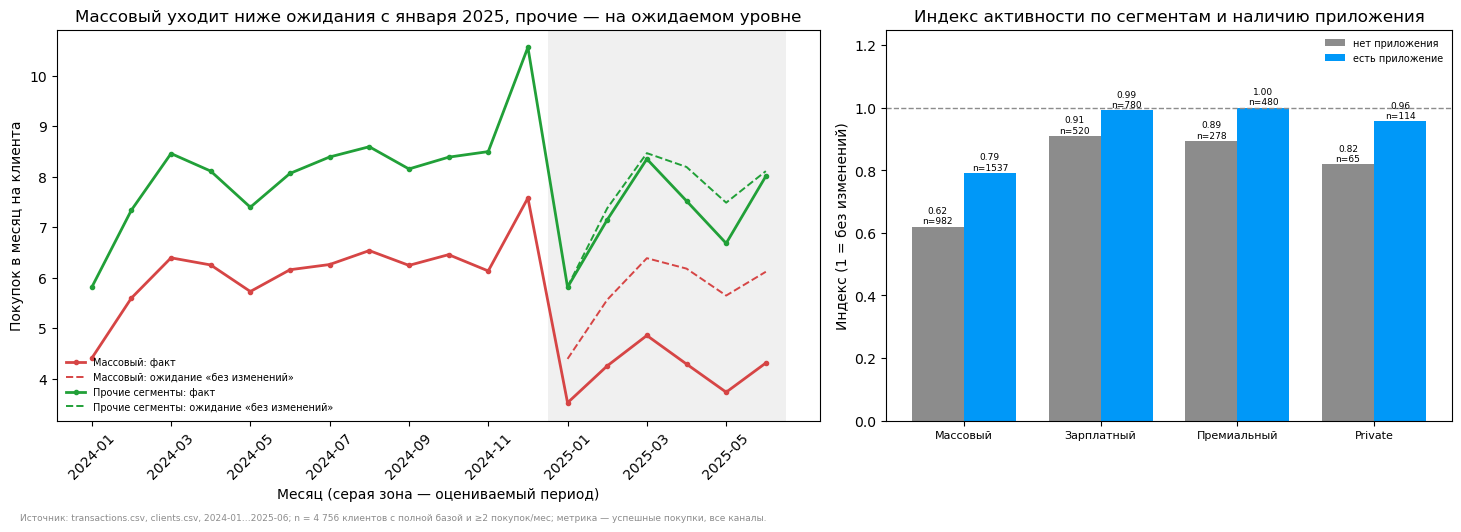


Индекс активности: Массовый **0.73** (n=2519), остальные сегменты **0.96** (n=2237). Среди Массового «нет приложения» — 0.62, «есть» — 0.79. Корреляция индекса с возрастом, доходом, стажем и базовым объёмом слабая (|ρ Спирмена| ≤ 0.12): падение определяется сегментом, а не одним числовым признаком.



In [34]:
#палитра для графика
RED         = "#D64545"
GREEN       = "#21A038"
BLUE        = "#0098F8"
GRAY        = "#8C8C8C"
GRAY_LIGHT  = "#E6E6E6"
PURPLE      = "#8A2BE2"
m = ops_long[ops_long.client_id.isin(el.client_id)].merge(
    el[["client_id", "mass", "base_pm", "segment", "has_mobile_app"]], on="client_id")

act = (m.groupby(["mass", "month"]).n_ops.mean()
         .unstack(0)
         .reindex([str(p) for p in ALL]))

tot2024 = m[m.month < "2025-01"].groupby("month").n_ops.sum()
season_m = (tot2024 / tot2024.mean()).values

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0),
                         gridspec_kw={"width_ratios": [1.35, 1]}, layout="constrained")

ax = axes[0]
for name, color in [("Массовый", RED), ("Прочие сегменты", GREEN)]:
    ax.plot(act.index, act[name], color=color, lw=2, marker="o", ms=3,
            label=f"{name}: факт")
    base_mean = el.loc[el.mass == name, "base_pm"].mean()
    ax.plot(act.index[12:], base_mean * season_m[:6], color=color, lw=1.4, ls="--",
            label=f"{name}: ожидание «без изменений»")
ax.axvspan(11.5, 17.5, color=GRAY_LIGHT, alpha=.6, lw=0)
ax.set_title("Массовый уходит ниже ожидания с января 2025, прочие — на ожидаемом уровне")
ax.set_ylabel("Покупок в месяц на клиента")
ax.set_xlabel("Месяц (серая зона — оцениваемый период)")
ax.set_xticks(range(0, 18, 2))
ax.set_xticklabels(act.index[::2], rotation=45)
ax.legend(frameon=False, fontsize=7, loc="lower left")

ax = axes[1]

g = el.groupby(["segment", "has_mobile_app"], observed=True)
t = pd.DataFrame({
    "n": g.size(),
    "r": g.apply(ratio, include_groups=False),
}).reset_index()

order = ["Массовый", "Зарплатный", "Премиальный", "Private"]
w = .38
for i, (app, lab, color) in enumerate([(False, "нет приложения", GRAY),
                                       (True,  "есть приложение", BLUE)]):
    s = t[t.has_mobile_app == app].set_index("segment").reindex(order)
    ax.bar(np.arange(4) + (i - .5) * w, s.r, w, color=color, label=lab)
    for x, r_, n_ in zip(np.arange(4) + (i - .5) * w, s.r, s.n):
        if pd.notna(r_):
            ax.text(x, r_ + .01, f"{r_:.2f}\nn={int(n_)}", ha="center", fontsize=6.5)
ax.axhline(1, color=GRAY, ls="--", lw=1)
ax.set_ylim(0, 1.25)
ax.set_xticks(range(4)); ax.set_xticklabels(order, fontsize=8)
ax.set_title("Индекс активности по сегментам и наличию приложения")
ax.set_ylabel("Индекс (1 = без изменений)")
ax.legend(frameon=False, fontsize=7, loc="upper right")

fig.text(0.01, -0.03,
         f"Источник: transactions.csv, clients.csv, 2024-01…2025-06; "
         f"n = {num(n_el)} клиентов с полной базой и ≥2 покупок/мес; "
         f"метрика — успешные покупки, все каналы.",
         fontsize=6.5, color=GRAY)
plt.show()

print(f"""
Индекс активности: Массовый **{r_mass:.2f}** (n={int((el.segment == 'Массовый').sum())}), остальные сегменты **{r_rest:.2f}** (n={int((el.segment != 'Массовый').sum())}). Среди Массового «нет приложения» — {r_noapp:.2f}, «есть» — {r_app:.2f}. Корреляция индекса с возрастом, доходом, стажем и базовым объёмом слабая (|ρ Спирмена| ≤ {rho_max:.2f}): падение определяется сегментом, а не одним числовым признаком.
""")

### 4.2. Клиенты стали платить реже, а не меньше; падение идёт по всем категориям, а часть оплат ушла в "Токен"

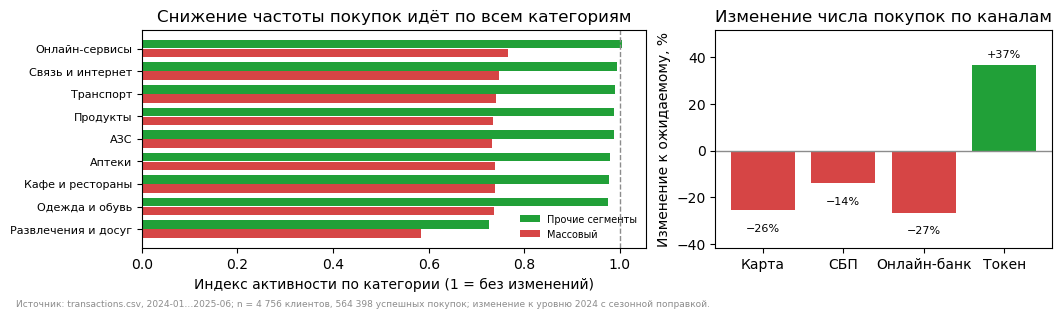


Медианный чек 2025/2024 = 0,89 (1123 → 1000 руб.): в основном падает частота, не размер покупки. Индекс активности снизился во всех категориях: сильнее всего — «Развлечения и досуг» (−42%), слабее всего — «Онлайн-сервисы» (+0%); нет ни одной категории, которая объяснила бы падение целиком. Канал «Карта» −26%, «Токен» +37%: активность, считаемая только по «Карте», завысила бы падение — отчасти это смена способа оплаты.



In [25]:
cat_b2 = (purch_el
          .merge(el[["client_id", "mass"]], on="client_id")
          .groupby(["category", "mass", "per"]).size()
          .unstack())
cat_r = ((cat_b2["eval"] / 6) / (cat_b2["base"] / 12) / S6).unstack()
cat_r = cat_r.loc[cat_r.mean(axis=1).sort_values().index]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 2.9),
                         gridspec_kw={"width_ratios": [1.5, 1]}, layout="constrained")

ax = axes[0]
y = np.arange(len(cat_r))
ax.barh(y + .2, cat_r["Прочие сегменты"], .38, color=GREEN, label="Прочие сегменты")
ax.barh(y - .2, cat_r["Массовый"],        .38, color=RED,   label="Массовый")
ax.axvline(1, color=GRAY, ls="--", lw=1)
ax.set_yticks(y)
ax.set_yticklabels(cat_r.index, fontsize=8)
ax.set_title("Снижение частоты покупок идёт по всем категориям")
ax.set_xlabel("Индекс активности по категории (1 = без изменений)")
ax.legend(frameon=False, fontsize=7, loc="lower right")

ax = axes[1]
chg = ch_change.reindex(["Карта", "СБП", "Онлайн-банк", "Токен"]) * 100
ax.bar(chg.index, chg.values, color=[RED if v < 0 else GREEN for v in chg.values])
for i, v in enumerate(chg.values):
    ax.text(i, v + (3 if v > 0 else -9), f"{v:+.0f}%".replace("-", "−"),
            ha="center", fontsize=8)
ax.axhline(0, color=GRAY, lw=1)
ax.set_ylim(chg.min() - 15, chg.max() + 15)
ax.set_title("Изменение числа покупок по каналам")
ax.set_ylabel("Изменение к ожидаемому, %")

fig.text(0.01, -0.04,
         f"Источник: transactions.csv, 2024-01…2025-06; n = {num(n_el)} клиентов, "
         f"{num(len(purch_el))} успешных покупок; изменение к уровню 2024 с сезонной поправкой.",
         fontsize=6.5, color=GRAY)
plt.show()


cat_min = cat_r.min(axis=1).idxmin()
cat_max = cat_r.max(axis=1).idxmax()
v_min = cat_r.min().min() - 1
v_max = cat_r.max().max() - 1
tk_str = f"{tk_ratio:.2f}".replace(".", ",")
print(f"""
Медианный чек 2025/2024 = {tk_str} ({tk['base']:.0f} → {tk['eval']:.0f} руб.): в основном падает частота, не размер покупки. Индекс активности снизился во всех категориях: сильнее всего — «{cat_min}» ({pc(v_min)}), слабее всего — «{cat_max}» ({pc(v_max)}); нет ни одной категории, которая объяснила бы падение целиком. Канал «Карта» {pc(ch_change['Карта'])}, «Токен» {pc(ch_change['Токен'])}: активность, считаемая только по «Карте», завысила бы падение — отчасти это смена способа оплаты.
""")

### 4.3. Падение не однородно по времени: Г1/Г2 затухают к концу периода, Г3/Г4 держатся стабильнее

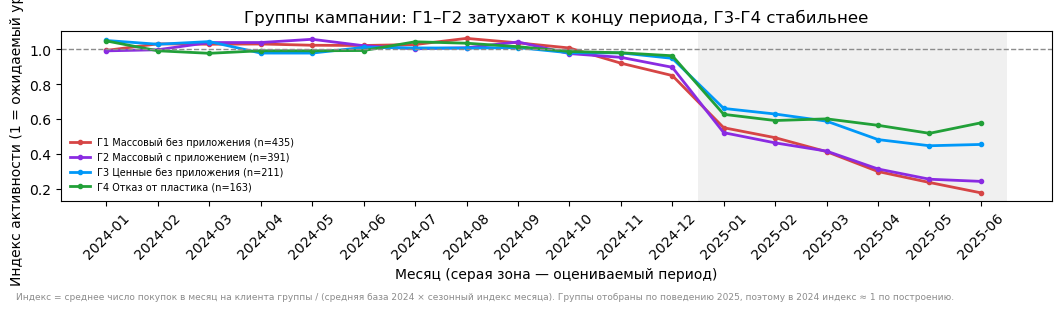

In [26]:
glabels = {
    groups[0]: ("Г1 Массовый без приложения", RED),
    groups[1]: ("Г2 Массовый с приложением", PURPLE),
    groups[2]: ("Г3 Ценные без приложения", BLUE),
    groups[3]: ("Г4 Отказ от пластика", GREEN),
}

mm = ops_long.merge(clean[["client_id", "group", "base_pm"]], on="client_id")
fig, ax = plt.subplots(figsize=(10.5, 2.8), layout="constrained")

for g, (lab, color) in glabels.items():
    d = mm[mm.group == g]
    s = d.groupby("month").n_ops.mean().reindex([str(p) for p in ALL]).values
    idx = s / (d.base_pm.mean() * np.concatenate([season_m, season_m[:6]]))
    
    ax.plot(range(18), idx, color=color, lw=2, marker="o", ms=3, 
            label=f"{lab} (n={len(d.client_id.unique())})")

ax.axhline(1, color=GRAY, ls="--", lw=1)
ax.axvspan(11.5, 17.5, color=GRAY_LIGHT, alpha=.6, lw=0)
ax.set_xticks(range(18))
ax.set_xticklabels([str(p) for p in ALL], rotation=45)
ax.set_ylabel("Индекс активности (1 = ожидаемый уровень)")
ax.set_xlabel("Месяц (серая зона — оцениваемый период)")
ax.set_title("Группы кампании: Г1–Г2 затухают к концу периода, Г3-Г4 стабильнее")
ax.legend(frameon=False, fontsize=7, loc="lower left")

fig.text(0.01, -0.05, 
         "Индекс = среднее число покупок в месяц на клиента группы / (средняя база 2024 × сезонный индекс месяца). "
         "Группы отобраны по поведению 2025, поэтому в 2024 индекс ≈ 1 по построению.", 
         fontsize=6.5, color=GRAY)
plt.show()

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->

In [27]:
clg = clean[clean.group.isin(groups)]

def profile(g):
    d = clg[clg.group == g]
    ids = d.client_id
    p = purch[purch.client_id.isin(ids)]
    c = p.groupby(["category", "per"]).size().unstack(fill_value=0)
    lost_c = (c["base"] / 12 * S6 - c["eval"] / 6)
    top = lost_c.sort_values(ascending=False)
    topcat = ", ".join(f"{k} {v / lost_c.sum():.0%}" for k, v in top.head(2).items())
    
    if g == groups[3]:
        c_ch = p.groupby(["channel", "per"]).size().unstack(fill_value=0)
        lost_ch = (c_ch["base"] / 12 * S6 - c_ch["eval"] / 6)
        top_ch = lost_ch.sort_values(ascending=False).head(1)
        topcat += f" (в осн. {top_ch.index[0]} {top_ch.iloc[0] / lost_ch.sum():.0%})"
        
    return dict(n=len(d), r6=d.ratio6.median(), r3=d.ratio3.median(), 
                base=d.base_pm.median(), ev=d.eval_pm.median(), topcat=topcat)

P = {g: profile(g) for g in groups}

rules = {
    groups[0]: "Сегмент «Массовый» и нет мобильного приложения и индекс активности янв–июнь ≤ 0,6 и апр–июнь ≤ 0,5",
    groups[1]: "Сегмент «Массовый» и есть мобильное приложение и те же пороги падения (≤ 0,6 и ≤ 0,5)",
    groups[2]: "Сегмент не «Массовый» и нет мобильного приложения и индекс активности янв–июнь ≤ 0,9 и апр–июнь ≤ 0,8",
    groups[3]: "Платил пластиком ≥ 0,85 раз/мес в 2024 и доля «Токена» ≤ 5% и индекс активности ≤ 0,8",
}

reasons = {
    groups[0]: "затухание: реже платят во всех категориях и каналах, «Токен» не компенсирует; чек не изменился",
    groups[1]: "общее снижение по всем категориям и каналам (включая «Токен») при установленном приложении; чек не изменился",
    groups[2]: "снижение в ценных сегментах без приложения; база дороже, поэтому потеря критичнее",
    groups[3]: "перестали пользоваться пластиком, но не перешли на «Токен»; общая частота упала",
}

tbl = pd.DataFrame([{
    "Группа": g.split(" ", 1)[0] + " " + g.split(" ", 1)[1].split(":")[0], 
    "Правило (кто + что произошло)": rules[g],
    "Размер": P[g]["n"], 
    "Индекс янв–июнь / апр–июнь (мед.)": f"{P[g]['r6']:.2f} / {P[g]['r3']:.2f}",
    "Покупок в мес. (мед.): 2024 → 2025": f"{P[g]['base']:.1f} → {P[g]['ev']:.1f}", 
    "За счёт чего (доля недобора)": P[g]["topcat"]
} for g in groups])


display(tbl)
print(f"""
Пересечения и приоритет. Под правила Г1–Г4 одновременно подходит лишь горстка клиентов; порядок разрешения: Г1 → Г2 → Г3 → Г4. Итого {num(len(camp))} уникальных клиентов (лимит 2 000), минимум в группе {gsize.min()} (порог 150). Около трети клиентов Г1/Г2 — «фон» индивидуальных колебаний (в других сегментах {bg[False]:.1%} клиентов формально подпадают под то же падение при среднем индексе {bg_ratio_rest:.2f}, у Массового — {bg[True]:.1%}): группа в целом реально упала, но отдельный клиент может быть ложным срабатыванием.
""")

,Группа,Правило (кто + что произошло),Размер,Индекс янв–июнь / апр–июнь (мед.),Покупок в мес. (мед.): 2024 → 2025,За счёт чего (доля недобора)
0,Г1 Массовый без приложения,Сегмент «Массовый» и нет мобильного приложения...,435,0.35 / 0.22,5.1 → 1.7,"Продукты 30%, Транспорт 12%"
1,Г2 Массовый с приложением,Сегмент «Массовый» и есть мобильное приложение...,391,0.36 / 0.26,5.4 → 1.7,"Продукты 30%, Транспорт 11%"
2,Г3 Ценные без приложения,Сегмент не «Массовый» и нет мобильного приложе...,211,0.54 / 0.47,7.8 → 3.3,"Продукты 22%, Развлечения и досуг 20%"
3,Г4 Отказ от пластика без перехода на Токен,"Платил пластиком ≥ 0,85 раз/мес в 2024 и доля ...",163,0.62 / 0.59,5.5 → 2.8,"Продукты 20%, Развлечения и досуг 19% (в осн. ..."



Пересечения и приоритет. Под правила Г1–Г4 одновременно подходит лишь горстка клиентов; порядок разрешения: Г1 → Г2 → Г3 → Г4. Итого 1 200 уникальных клиентов (лимит 2 000), минимум в группе 163 (порог 150). Около трети клиентов Г1/Г2 — «фон» индивидуальных колебаний (в других сегментах 12.5% клиентов формально подпадают под то же падение при среднем индексе 0.96, у Массового — 37.1%): группа в целом реально упала, но отдельный клиент может быть ложным срабатыванием.



## 6. Кого не включаем и почему

<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->

In [28]:
ex = clean.exclusion_reason.value_counts()
ex = ex[~ex.index.str.contains("кампании", case=False, na=False)]

shorts = {
    "Активность не сильно упала (индекс ≥ 0,85) или выросла": "Активность не упала — кампания не нужна",
    "Нет полного базового года: карта открыта в 2024–2025": "Карта открыта в 2024–2025 — нет базового года",
    "Умеренное снижение (индекс 0,6–0,85), не попал в целевые группы": "Умеренное снижение (0,6–0,85) — не дотягивает до порога",
    "Нет согласия на маркетинговую коммуникацию": "Нет согласия на коммуникацию — связаться нельзя",
    "Общее падение, но не попал в целевые группы": "Падение вне целевых групп — на уровне фонового шума",
    "Перешли с «Карты» на «Токен»: общая активность держится (падение только в пластике)": "Перешли с «Карты» на «Токен» — активность держится",
    "Мало операций в базе (<2 в месяц): падение не измерить": "Менее 2 покупок в месяц в 2024 — индекс шумит",
}

ex_tbl = pd.DataFrame({
    "Кого не берём": [shorts.get(k, k) for k in ex.index], 
    "Клиентов": ex.values,
    f"Доля, % (из {num(n_ref)})": (ex.values / n_ref * 100).round(1)
})

extra = pd.DataFrame({
    "Кого не берём": ["Клиенты вне справочника — ушли из банка"], 
    "Клиентов": [orph], 
    f"Доля, % (из {num(n_ref)})": ["—"]
})

display(pd.concat([ex_tbl, extra], ignore_index=True))

# Считаем согласие с учётом всех 4 групп
nconsent = int(((~clean.opt_in) & clean.eligible_base & 
                (clean.rule_g1 | clean.rule_g2 | clean.rule_g3 | clean.rule_g4)).sum())

print(f"Среди клиентов без согласия {nconsent} подошли бы под правила Г1–Г4 — это упущенная аудитория, которую можно вернуть сбором согласий. Клиентов, перешедших на «Токен», кампания «вернуть активность» только раздражала бы.")

,Кого не берём,Клиентов,"Доля, % (из 5 673)"
0,Активность не упала — кампания не нужна,2117,37.3
1,Карта открыта в 2024–2025 — нет базового года,772,13.6
2,"Умеренное снижение (0,6–0,85) — не дотягивает ...",600,10.6
3,Нет согласия на коммуникацию — связаться нельзя,570,10.0
4,Перешли с «Карты» на «Токен» — активность держ...,188,3.3
5,Менее 2 покупок в месяц в 2024 — индекс шумит,133,2.3
6,Падение вне целевых групп — на уровне фонового...,93,1.6
7,Клиенты вне справочника — ушли из банка,327,—


Среди клиентов без согласия 181 подошли бы под правила Г1–Г4 — это упущенная аудитория, которую можно вернуть сбором согласий. Клиентов, перешедших на «Токен», кампания «вернуть активность» только раздражала бы.


## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->

In [29]:
h = hyp.copy(); h.columns = ["Гипотеза", "Результат (с числом)"]
display(HTML(h.to_html(index=False)))

Гипотеза,Результат (с числом)
"H1. Падение только в канале «Карта», а в целом активность не упала","НЕ подтвердилась: «Карта» -26%, «Токен» +37%, но суммарно по всем каналам -15% (n=4756). Переход в «Токен» компенсирует лишь часть."
H2. Падение связано с городом (Казань хуже),"НЕ подтвердилась: по всем клиентам Казань 0.87 против 0.85, но внутри Массового сегмента Казань 0.73 против 0.73 — эффект города = состав сегмента."
H3. Не заходят в приложение ≥6 мес. → активность упала сильнее,НЕ подтвердилась: ratio 0.90 (n=1920) против 0.91 при входе ≤1 мес. назад (n=333); различие в пределах шума.
H4. Клиенты стали платить меньшими суммами (упал чек),"НЕ подтвердилась: медианный чек 2025/2024 = 0.89 (≈ 1123 → 1000 руб.); упала частота операций, а не размер покупки."
H5. Недовольные (оценка 1–2) снижают активность сильнее довольных (4–5),"СЛАБО/не подтвердилась: ratio 0.83 (n=621) против 0.86 (n=847); оценка есть только у 40% клиентов, вывод ненадёжен."
H6. Внутри Массового сегмента падение больше у получающих зарплату в другом банке,НЕ подтвердилась: ratio 0.72 (n=884) против 0.76 (n=614).


## 8. Приложение

### 8.1. Сводка журнала изменений

<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->

In [38]:
# 8.1. Сводка журнала изменений — 8 строк по типам нарушений
compact = pd.DataFrame([
    {"Поле / нарушение": "monthly_income",
     "Что найдено": "−999, тыс. руб., пропуски",
     "Строк": 921,
     "Решение": "исправлено / заполнено"},
    {"Поле / нарушение": "txn_datetime",
     "Что найдено": "вне периода 2024–2025; только дата без времени",
     "Строк": 50_528,
     "Решение": "удалено / оставлено с флагом"},
    {"Поле / нарушение": "category, mcc_code",
     "Что найдено": "12 написаний вместо 9; mcc не соответствует категории",
     "Строк": 53_587,
     "Решение": "нормализовано"},
    {"Поле / нарушение": "amount, amount_rub",
     "Что найдено": "EUR/USD, выбросы по суммам",
     "Строк": 38_074,
     "Решение": "конвертация / оставлено"},
    {"Поле / нарушение": "txn_id, client_id",
     "Что найдено": "полные дубли и повторы id",
     "Строк": 1_555,
     "Решение": "удалено"},
    {"Поле / нарушение": "city, segment",
     "Что найдено": "разнобой написания; конфликты по id",
     "Строк": 1_704,
     "Решение": "нормализация / NaN с флагом"},
    {"Поле / нарушение": "satisfaction_score, app_last_login",
     "Что найдено": "структурные пропуски",
     "Строк": 5_620,
     "Решение": "оставлено"},
])
display(compact.style.hide(axis="index"))

Поле / нарушение,Что найдено,Строк,Решение
monthly_income,"−999, тыс. руб., пропуски",921,исправлено / заполнено
txn_datetime,вне периода 2024–2025; только дата без времени,50528,удалено / оставлено с флагом
"category, mcc_code",12 написаний вместо 9; mcc не соответствует категории,53587,нормализовано
"amount, amount_rub","EUR/USD, выбросы по суммам",38074,конвертация / оставлено
"txn_id, client_id",полные дубли и повторы id,1555,удалено
"city, segment",разнобой написания; конфликты по id,1704,нормализация / NaN с флагом
"satisfaction_score, app_last_login",структурные пропуски,5620,оставлено


### 8.2. Методика


In [31]:
display(Markdown(f"""
* **Покупка и допуск.** `status = «успешно»`, 2024-01-01…2025-06-30, клиент из справочника без конфликта `client_id`; каналы — Карта, Токен, СБП, Онлайн-банк. Допуск: `card_open_date ≤ 2023-12-31` **и** `base_pm ≥ 2.0`.

* **Формулы.** `base_pm` = покупок за 2024 / 12; `eval_pm` = покупок за январь–июнь 2025 / 6.
  `S6` = сезонный индекс янв–июнь (по клиентам с полным базовым годом) = **{S6:.3f}**; `S3` (апр–июнь) = **{clean.season_S3.iloc[0]:.3f}**.
  `ratio6 = eval_pm / (base_pm · S6)`; `ratio3` — то же за апрель–июнь 2025 с `S3`.

* **Пороги.** Широкое падение (Г1, Г2): `ratio6 ≤ 0,6` **и** `ratio3 ≤ 0,5`. Ценные без приложения (Г3): `ratio6 ≤ 0,85` **и** `ratio3 ≤ 0,8`. Отказ от пластика (Г4): `card_base_pm ≥ 0,85` **и** `token_share ≤ 0,05` **и** `ratio6 ≤ 0,8`. Устойчивость: при ужесточении Г1/Г2 до 0,5/0,4 остаётся {keep(False, .5, .4):.0%} и {keep(True, .5, .4):.0%} состава, при ослаблении до 0,7/0,6 — {keep(False, .7, .6):.0%} и {keep(True, .7, .6):.0%}; без сезонной поправки — {keep(False, .6, .5, 'ratio6_raw', 'ratio3_raw'):.0%} и {keep(True, .6, .5, 'ratio6_raw', 'ratio3_raw'):.0%}.

* **Расчёты и воспроизводимость.** Валютные суммы — по среднемесячным курсам ЦБ РФ (словарь `FX_MONTHLY`); на метрику (число операций) не влияет. Меры центра/разброса: медиана и МКР/МАО для дохода, чеков и числа операций (правая асимметрия); среднее и σ — только для возраста и стажа. Квартили — линейная интерполяция; ML и scipy не использовались. Воспроизведение: `01_analysis.ipynb` → `02_report.ipynb`.
"""))


* **Покупка и допуск.** `status = «успешно»`, 2024-01-01…2025-06-30, клиент из справочника без конфликта `client_id`; каналы — Карта, Токен, СБП, Онлайн-банк. Допуск: `card_open_date ≤ 2023-12-31` **и** `base_pm ≥ 2.0`.

* **Формулы.** `base_pm` = покупок за 2024 / 12; `eval_pm` = покупок за январь–июнь 2025 / 6.
  `S6` = сезонный индекс янв–июнь (по клиентам с полным базовым годом) = **0.930**; `S3` (апр–июнь) = **0.973**.
  `ratio6 = eval_pm / (base_pm · S6)`; `ratio3` — то же за апрель–июнь 2025 с `S3`.

* **Пороги.** Широкое падение (Г1, Г2): `ratio6 ≤ 0,6` **и** `ratio3 ≤ 0,5`. Ценные без приложения (Г3): `ratio6 ≤ 0,85` **и** `ratio3 ≤ 0,8`. Отказ от пластика (Г4): `card_base_pm ≥ 0,85` **и** `token_share ≤ 0,05` **и** `ratio6 ≤ 0,8`. Устойчивость: при ужесточении Г1/Г2 до 0,5/0,4 остаётся 81% и 76% состава, при ослаблении до 0,7/0,6 — 100% и 100%; без сезонной поправки — 100% и 100%.

* **Расчёты и воспроизводимость.** Валютные суммы — по среднемесячным курсам ЦБ РФ (словарь `FX_MONTHLY`); на метрику (число операций) не влияет. Меры центра/разброса: медиана и МКР/МАО для дохода, чеков и числа операций (правая асимметрия); среднее и σ — только для возраста и стажа. Квартили — линейная интерполяция; ML и scipy не использовались. Воспроизведение: `01_analysis.ipynb` → `02_report.ipynb`.


### 8.3. Использование ИИ

In [32]:
display(Markdown(
"Использовал LLM для оформления результатов, проверки кода и обсуждения разумности решений. "
"Отдельно проверил сам: кодировки и разделители файлов, гипотезу о том, что `category` надёжнее "
"`mcc_code` (суммы ближе к медиане категории), и что значения `monthly_income < 1000` — не выбросы, "
"а запись в тысячах рублей."
))

Использовал LLM для оформления результатов, проверки кода и обсуждения разумности решений. Отдельно проверил сам: кодировки и разделители файлов, гипотезу о том, что `category` надёжнее `mcc_code` (суммы ближе к медиане категории), и что значения `monthly_income < 1000` — не выбросы, а запись в тысячах рублей.